In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

In [2]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

In [4]:
# build the vocabulary of characters and mappings to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}
print(itos)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}


In [77]:
block_size = 3 # this defines the input context given to the NN to predict the next character - in this case, 3 previous characters are used.
X, Y = [], [] # x is the inputs, y is the corresponding labels for input x

for w in words:
    # print(w)
    context = [0] * block_size # initializing the input context
    for ch in w + ".":
        ix = stoi[ch] # get the char in the sequence
        X.append(context) # input context
        Y.append(ix) #output for the input context
        # print(''.join(itos[i] for i in context), '-------->', itos[ix])
        context = context[1:] + [ix] # --> slide the window forward!

X = torch.tensor(X)
Y = torch.tensor(Y)

In [132]:
# build the dataset
block_size = 3 # context length: how many characters do we take to predict the next one?

def build_dataset(words):  
  X, Y = [], []
  for w in words:

    #print(w)
    context = [0] * block_size
    for ch in w + '.':
      ix = stoi[ch]
      X.append(context)
      Y.append(ix)
      #print(''.join(itos[i] for i in context), '--->', itos[ix])
      context = context[1:] + [ix] # crop and append

  X = torch.tensor(X)
  Y = torch.tensor(Y)
  print(X.shape, Y.shape)
  return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182580, 3]) torch.Size([182580])
torch.Size([22767, 3]) torch.Size([22767])
torch.Size([22799, 3]) torch.Size([22799])


In [78]:
X, Y

(tensor([[ 0,  0,  0],
         [ 0,  0,  5],
         [ 0,  5, 13],
         ...,
         [26, 26, 25],
         [26, 25, 26],
         [25, 26, 24]]),
 tensor([ 5, 13, 13,  ..., 26, 24,  0]))

In [16]:
# let's now take the 27 characters (26 + 1 sepcial) and cram it into a small dimensional space. this ensures that similar character sequences are crammed closer together.
# in the vector space. In this case, we cram it into a 2D space.
C = torch.randn((27, 2))
emb = C[X]
emb.shape

torch.Size([32, 3, 2])

In [17]:
W1 = torch.randn((6, 100))
b1 = torch.randn(100)

In [19]:
emb @ W1 + b # the matrices CANNOT be multiplied. 

RuntimeError: mat1 and mat2 shapes cannot be multiplied (96x2 and 6x100)

In [23]:
# Hence, we want to now concatenate all 3 lookup tables
torch.cat([emb[:, 0, :], emb[:, 1, :], emb[:, 2, :]], 1).shape


torch.Size([32, 6])

In [28]:
torch.cat(torch.unbind(emb, 1), 1).shape # cleaner way of doing what we did in cell 23 with torch.cat()

torch.Size([32, 6])

In [32]:
# even better way of doing cell 23 - with a.view() function - in which we can view a tensor in any shape, as long as the numbers multiply to the same answer
# e.g: a.view[9, 2] ==> a.view[3, 3, 2] ==> a.view[18, 1] ----> all view operations basically change the vector dimensions of the same vector so we can view it in the correct dimension set.

h = emb.view(-1, 6) @ W1 + b1
h.shape

torch.Size([32, 100])

In [37]:
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # activation function for normalization b/w -1 and 1
h

tensor([[-0.8971,  0.6562,  0.0609,  ...,  0.5727,  0.7113, -0.3032],
        [-0.2631,  0.7298,  0.9593,  ...,  0.5728,  0.9771, -0.0468],
        [-0.9999,  0.0205, -0.1412,  ...,  0.9977, -0.9259,  0.8198],
        ...,
        [ 0.9805, -0.9048,  0.9995,  ...,  0.8344,  0.9778,  0.5712],
        [-0.7680, -0.9734,  0.9666,  ...,  0.9891,  0.3847,  0.8245],
        [ 0.2974, -0.9381, -0.9793,  ..., -0.4026,  0.7963, -0.7567]])

In [38]:
W2 = torch.randn((100, 27))
b2 = torch.randn(27)

In [39]:
logits = h @ W2 + b2

In [40]:
logits.shape

torch.Size([32, 27])

In [41]:
counts = logits.exp()
prob = counts / counts.sum(1, keepdims=True)

In [42]:
prob[0].sum()

tensor(1.)

In [44]:
loss = -prob[torch.arange(32), Y].log().mean()

In [45]:
loss

tensor(16.4277)

In [ ]:
emb = C[X]
h = torch.tanh(emb.view(-1, 6) @ W1 + b1) # activation function for normalization b/w -1 and 1
logits = h @ W2 + b2
# counts = logits.exp()
# prob = counts / counts.sum(1, keepdims=True)
# loss = -prob[torch.arange(32), Y].log().mean()
loss = F.cross_entropy(logits, Y) # basically does the same thing as the commented out code, is a built in function in torch

In [185]:
# ------------------ putting it all together !!! -----------------------------

Xtr.shape, Ytr.shape

(torch.Size([182580, 3]), torch.Size([182580]))

In [186]:
g = torch.Generator().manual_seed(2147483647) # for reproducibility
C = torch.randn((27, 10), generator=g)
W1 = torch.randn((30, 200), generator=g)
b1 = torch.randn(200, generator=g)
W2 = torch.randn((200, 27), generator=g)
b2 = torch.randn(27, generator=g)
parameters = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parameters))

11897


In [187]:
for p in parameters:
    p.requires_grad = True

In [183]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10**lre

In [188]:
lri = []
losses = []
stepi = []

In [205]:
# Now for the neural network loop:

# forward pass:
for i in range(200000):

    # minibatch construct to optimize for large data and many iterations:

    ix = torch.randint(0, Xtr.shape[0], (32,))
    
    emb = C[Xtr[ix]]
    h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
    logits = h @ W2 + b2
    loss = F.cross_entropy(logits, Ytr[ix])

    # print(loss.item())
    # backward pass
    
    for p in parameters:
        p.grad = None
    loss.backward()
    
    # update
    # lr = lrs[i]
    lr = 0.1 if i < 100000 else 0.01
    
    for p in parameters:
        p.data += -lr * p.grad

    #track the stats:
    # lri.append(lre[i])
    stepi.append(i)
    losses.append(loss.log10().item())

print(loss.item())

1.859061360359192


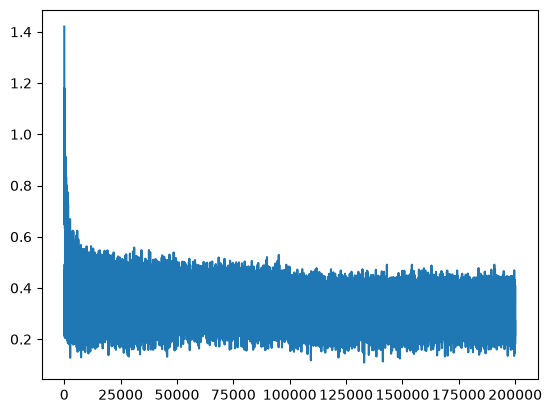

In [206]:
plt.plot(stepi, losses)

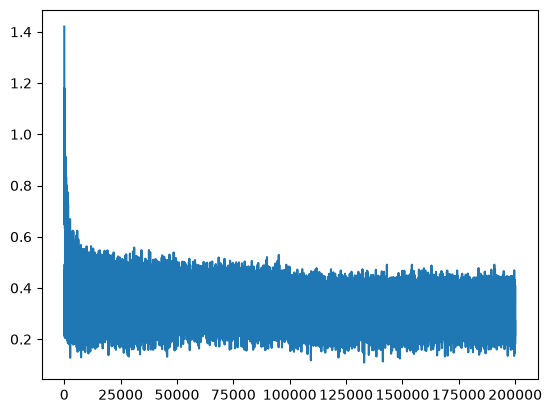

In [207]:
plt.plot(stepi, losses)

In [208]:
# dev/validation set loss

emb = C[Xdev]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ydev)
loss

tensor(2.1377, grad_fn=<NllLossBackward0>)

In [209]:
# training set loss

emb = C[Xtr]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Ytr)
loss

tensor(2.0915, grad_fn=<NllLossBackward0>)

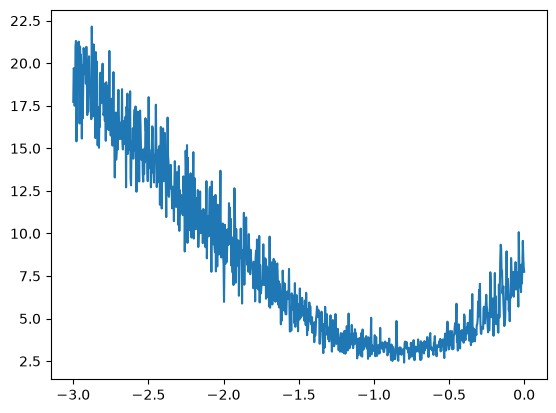

In [114]:
plt.plot(lri, losses)

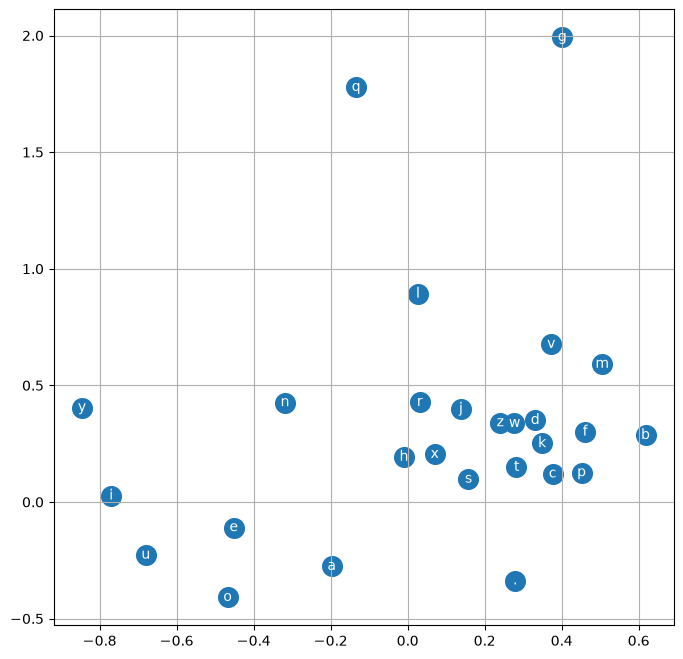

In [177]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [210]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)

for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      emb = C[torch.tensor([context])] # (1,block_size,d)
      h = torch.tanh(emb.view(1, -1) @ W1 + b1)
      logits = h @ W2 + b2
      probs = F.softmax(logits, dim=1)
      ix = torch.multinomial(probs, num_samples=1, generator=g).item()
      context = context[1:] + [ix]
      out.append(ix)
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out))

carmah.
ambrie.
khyrmish.
taty.
skaeson.
jazon.
nadelynn.
jareei.
nellara.
chaiir.
kaleigh.
ham.
pristeniyah.
roix.
alianni.
watelogiearyxia.
kael.
dura.
med.
edi.


In [211]:
# training set loss

emb = C[Xte]
h = torch.tanh(emb.view(-1, 30) @ W1 + b1)
logits = h @ W2 + b2
loss = F.cross_entropy(logits, Yte)
loss

tensor(2.1433, grad_fn=<NllLossBackward0>)